In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math

import tensorflow as tf

# Keras Sequential Model
from tensorflow.keras.models import Sequential

# Importing all the different layers and optimizers
from tensorflow.keras.layers import Dense, Dropout, Flatten, Conv2D, MaxPooling2D, BatchNormalization, Activation, LeakyReLU
from tensorflow.keras.optimizers import Adam,SGD

# The below code can be used to ignore the warnings that may occur due to deprecations
import warnings
warnings.filterwarnings("ignore")


In [2]:
# Loading the data
from tensorflow.keras.datasets import mnist
(X_train, y_train), (X_test, y_test) = mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 32s 3us/step


In [3]:
X_train.shape

(60000, 28, 28)

In [4]:
X_train[0]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,
         18,  18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,
          0,   0],
       [  

In [6]:
y_train[0]

np.uint8(5)

In [7]:
X_test.shape

(10000, 28, 28)

## **Data Visualization**

#### Converting the Numpy arrays to images and visualizing a few random images

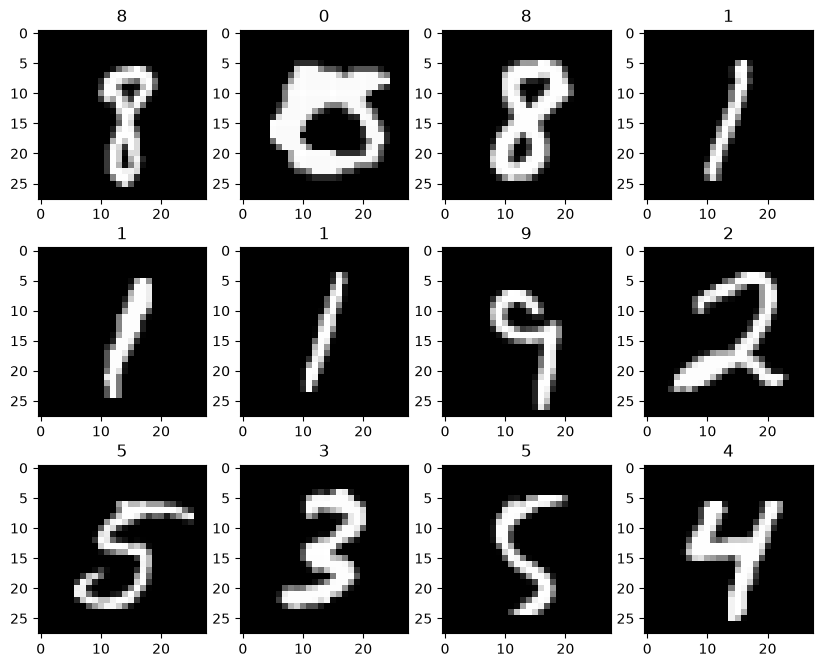

In [8]:
num_classes=10                                                                  # Number of Classes
categories=np.unique(y_train)                                                   # Obtaing the unique classes from y_train
rows = 3                                                                        # Defining number of rows=3
cols = 4                                                                        # Defining number of columns=4
fig = plt.figure(figsize=(10, 8))                                               # Defining the figure size to 10x8
for i in range(cols):
    for j in range(rows):
        random_index = np.random.randint(0, len(y_train))                       # Generating random indices from the data and plotting the images
        ax = fig.add_subplot(rows, cols, i * rows + j + 1)                      # Adding subplots with 3 rows and 4 columns
        ax.imshow(X_train[random_index, :], cmap=plt.get_cmap('gray'))          # Plotting the image using cmap=gray
        ax.set_title(categories[y_train[random_index]])
plt.show()

## **Data Preparation**

In [11]:
# Reshape dataset to have a single channel
X_train = X_train.reshape((X_train.shape[0], 28, 28, 1))
X_test = X_test.reshape((X_test.shape[0], 28, 28, 1))

In [12]:
# Normalizing the image pixels
X_train_normalized = X_train.astype('float32')/255.0
X_test_normalized = X_test.astype('float32')/255.0

In [13]:
# Creating one-hot encoded representation of target labels

y_train_encoded = tf.keras.utils.to_categorical(y_train)
y_test_encoded = tf.keras.utils.to_categorical(y_test)

## **Model Building - Artificial Neural Network (ANN)**

In [14]:
# Fixing the seed for random number generators
import random
np.random.seed(42)
random.seed(42)
tf.random.set_seed(42)

In [15]:
# Intializing a sequential model
ann_model = Sequential()

# Flatten the input to add dense convolutional layers on top of it
ann_model.add(Flatten(input_shape=(28, 28)))

# Adding a sequential layer with 100 neurons
ann_model.add(Dense(100, activation='relu'))

# Adding the output layer with 10 neurons and activation functions as softmax since this is a multi-class classification problem  
ann_model.add(Dense(10, activation='softmax'))

# Using SGD Optimizer
opt = SGD(learning_rate=0.01, momentum=0.9)

# Compile model
ann_model.compile(optimizer=opt,
              loss='categorical_crossentropy',
              metrics=['accuracy'])

# Generating the summary of the model
ann_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 100)            │        78,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 79,510 (310.59 KB)

 Trainable params: 79,510 (310.59 KB)

 Non-trainable params: 0 (0.00 B)

*  **Flatten Layer** <br>
Here, the input shape to the layer is (28,28)<br>
It does not have any parameters, so the number of parameters is 0.<br>

*   **Fully Connected Dense Layer**<br>
Number of neurons: 100<br>
Number of parameters: (784x100)+(1x100): 78400+100: 78500<br>
` Number of neurons in current layer x number of neurons in the previous layer + 1 x number of neurons in current layer(Bias)`<br>

*   **Output Layer**<br>
Number of neurons: 10<br>
Number of parameters: (10x100)+(1x10) = 1010<br>
` Number of neurons in current layer x number of neurons in the previous layer( Here in the previous dense layer: 100) + 1 x number of neurons in current layer(Bias)`








<b> Fitting the model on the train data:

In [16]:
history = ann_model.fit(
            X_train_normalized, y_train_encoded,
            epochs=15,
            validation_split=0.1,
            shuffle=True,
            batch_size=64,
            verbose=2
)

Epoch 1/15
844/844 - 30s - 36ms/step - accuracy: 0.8861 - loss: 0.4072 - val_accuracy: 0.9443 - val_loss: 0.2013
Epoch 2/15
844/844 - 5s - 6ms/step - accuracy: 0.9388 - loss: 0.2151 - val_accuracy: 0.9593 - val_loss: 0.1459
Epoch 3/15
844/844 - 6s - 7ms/step - accuracy: 0.9535 - loss: 0.1631 - val_accuracy: 0.9653 - val_loss: 0.1210
Epoch 4/15
844/844 - 5s - 6ms/step - accuracy: 0.9630 - loss: 0.1332 - val_accuracy: 0.9690 - val_loss: 0.1068
Epoch 5/15
844/844 - 5s - 6ms/step - accuracy: 0.9683 - loss: 0.1134 - val_accuracy: 0.9710 - val_loss: 0.0975
Epoch 6/15
844/844 - 5s - 5ms/step - accuracy: 0.9724 - loss: 0.0988 - val_accuracy: 0.9738 - val_loss: 0.0914
Epoch 7/15
844/844 - 5s - 5ms/step - accuracy: 0.9753 - loss: 0.0874 - val_accuracy: 0.9747 - val_loss: 0.0866
Epoch 8/15
844/844 - 5s - 6ms/step - accuracy: 0.9779 - loss: 0.0782 - val_accuracy: 0.9757 - val_loss: 0.0833
Epoch 9/15
844/844 - 5s - 6ms/step - accuracy: 0.9806 - loss: 0.0706 - val_accuracy: 0.9763 - val_loss: 0.0807

### **Model Evaluation**

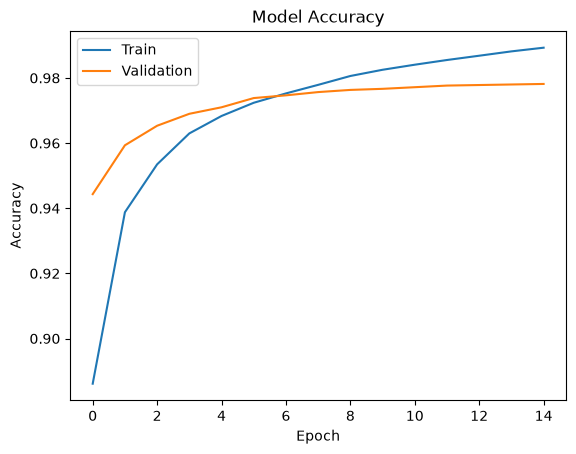

In [17]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

**Observations:** 

*   From the above plot,the model has perfomed well on the train and validation data, with a **validation accuracy of 97%.**


### **Evaluating the model on the test data**

In [18]:
accuracy = ann_model.evaluate(X_test_normalized, y_test_encoded, verbose=2)

313/313 - 4s - 12ms/step - accuracy: 0.9758 - loss: 0.0800


### **Generating the Predictions using the test data**

In [19]:
# Here we would get the output as probablities for each category
y_pred=ann_model.predict(X_test_normalized)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step


### **Plotting the Confusion Matrix**

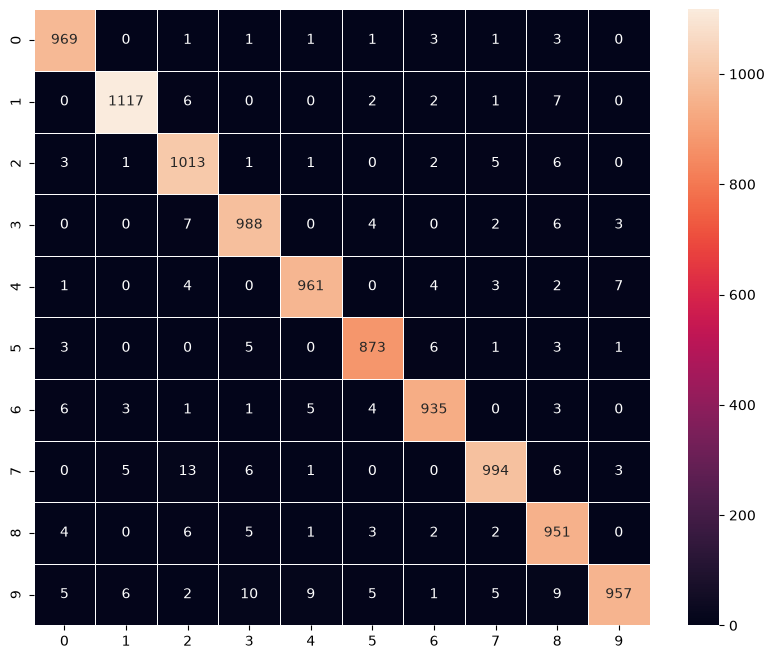

In [20]:
# Obtaining the categorical values from y_test_encoded and y_pred
y_pred_arg=np.argmax(y_pred,axis=1)
y_test_arg=np.argmax(y_test_encoded,axis=1)

# Plotting the Confusion Matrix using confusion matrix() function which is also predefined tensorflow module
confusion_matrix = tf.math.confusion_matrix(y_test_arg,y_pred_arg)
f, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    confusion_matrix,
    annot=True,
    linewidths=.4,
    fmt="d",
    square=True,
    ax=ax
)
plt.show()

**We observe that most of the classes are predicted correctly**, and the misclassification occurs mostly with the digit 4 which is sometimes confused with digit 9, and digit 5 which is sometimes confused with digit 3.

## **Model Building - Convolutional Neural Network (CNN)**

In [21]:
# Clearing backend
from tensorflow.keras import backend
backend.clear_session()

In [22]:
 # Fixing the seed for random number generators
import random
np.random.seed(42)
random.seed(42)
tf.random.set_seed(42)

In [23]:
# Intializing a sequential model
model = Sequential()

# Adding first conv layer with 64 filters and kernel size 3x3 , padding 'same' provides the output size same as the input size
# Input_shape denotes input image dimension of MNIST images
model.add(Conv2D(64, (3, 3), activation='relu', padding="same", input_shape=(28, 28, 1)))

# Adding max pooling to reduce the size of output of first conv layer
model.add(MaxPooling2D((2, 2), padding = 'same'))

model.add(Conv2D(32, (3, 3), activation='relu', padding="same"))
model.add(MaxPooling2D((2, 2), padding = 'same'))
model.add(Conv2D(32, (3, 3), activation='relu', padding="same"))
model.add(MaxPooling2D((2, 2), padding = 'same'))

# flattening the output of the conv layer after max pooling to make it ready for creating dense connections
model.add(Flatten())

# Adding a fully connected dense layer with 100 neurons    
model.add(Dense(100, activation='relu'))

# Adding the output layer with 10 neurons and activation functions as softmax since this is a multi-class classification problem  
model.add(Dense(10, activation='softmax'))

# Using SGD Optimizer
opt = SGD(learning_rate=0.01, momentum=0.9)

# Compile model
model.compile(optimizer=opt, loss='categorical_crossentropy', metrics=['accuracy'])

# Generating the summary of the model
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 32)       │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 100)            │        51,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 80,662 (315.09 KB)

 Trainable params: 80,662 (315.09 KB)

 Non-trainable params: 0 (0.00 B)

**The parameters in the CNN layers:**
> 

*  **First Conv2D Layer** <br>
The input shape to the Conv2D layer: (28,28,1)<br>
The Size of the Filter: 3x3 <br>
The Number of Filters: 64<br>
The Number of parameters: (3x3x1+1)x64 = 640<br>
  `(width of filter in current layer x height of filter in current layer x number of filters in previous layer + bias) x number of filters in current layer`<br>

*   **Max Pooling Layer**<br>
Pooling has no trainable parameters, so the number of parameters: 0<br>

*   **Flatten**<br>
It does not have any trainable parameters, so the number of parameters: 0<br>

*   **Fully Connected Dense Layer**<br>
Number of neurons: 100<br>
Number of parameters: (100x512)+(1x100): 51300<br>
` Number of neurons in current layer x number of neurons in the previous layer (Here in max pooling layer: 14x14x16) + 1 x number of neurons in current layer (Bias)`<br>

*   **Output Layer**<br>
Number of neurons: 10<br>
Number of parameters: (10x100)+(1x10)=1010<br>
` Number of neurons in current layer x number of neurons in the previous layer (Here in the previous dense layer: 128) + 1 x number of neurons in current layer(Bias)`








### <b> Fitting the model on the train data

In [24]:
history_1 = model.fit(
            X_train_normalized, y_train_encoded,
            epochs=15,
            validation_split=0.1,
            shuffle=True,
            batch_size=64,
            verbose=2
)

Epoch 1/15
844/844 - 88s - 104ms/step - accuracy: 0.8895 - loss: 0.3442 - val_accuracy: 0.9757 - val_loss: 0.0812
Epoch 2/15
844/844 - 50s - 59ms/step - accuracy: 0.9775 - loss: 0.0720 - val_accuracy: 0.9852 - val_loss: 0.0508
Epoch 3/15
844/844 - 46s - 54ms/step - accuracy: 0.9842 - loss: 0.0503 - val_accuracy: 0.9870 - val_loss: 0.0468
Epoch 4/15
844/844 - 47s - 56ms/step - accuracy: 0.9873 - loss: 0.0394 - val_accuracy: 0.9882 - val_loss: 0.0420
Epoch 5/15
844/844 - 85s - 101ms/step - accuracy: 0.9901 - loss: 0.0314 - val_accuracy: 0.9863 - val_loss: 0.0468
Epoch 6/15
844/844 - 50s - 59ms/step - accuracy: 0.9916 - loss: 0.0259 - val_accuracy: 0.9813 - val_loss: 0.0616
Epoch 7/15
844/844 - 81s - 96ms/step - accuracy: 0.9932 - loss: 0.0218 - val_accuracy: 0.9803 - val_loss: 0.0691
Epoch 8/15
844/844 - 50s - 59ms/step - accuracy: 0.9946 - loss: 0.0183 - val_accuracy: 0.9817 - val_loss: 0.0673
Epoch 9/15
844/844 - 50s - 60ms/step - accuracy: 0.9954 - loss: 0.0150 - val_accuracy: 0.9805 